# B02-GN — GMM trên RFM (log1p F,M; giữ R; Standard + PCA 90%)

Thí nghiệm **B02-GN** (người chạy: An) theo chiến lược model. So với B01, **chỉ khác ở Recency**: B01 log1p cả R,F,M; B02 chỉ log1p Frequency và Monetary, **giữ Recency nguyên**. Mục đích: đối chứng xem biến đổi Recency có cần thiết hay không.

Mọi tham số GMM khác (seed, lưới k×covariance, quy tắc chọn) giữ nguyên như B01-GN để so sánh trực tiếp.

## Params

In [1]:
FEATURES = ["Recency", "Frequency", "Monetary"]
LOG_COLS = ["Frequency", "Monetary"]   # khác B01: Recency KHÔNG log1p
PCA_VAR = 0.90
RANDOM_STATE = 42
N_INIT = 10
MAX_ITER = 300
TOL = 1e-3
REG_COVAR = 1e-6
INIT_PARAMS = "kmeans"
K_RANGE = range(2, 11)
COV_TYPES = ["full", "tied", "diag", "spherical"]
MIN_CLUSTER_FRAC = 0.01

## Import thư viện và đọc dữ liệu

In [2]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.pipeline import Pipeline
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score

warnings.filterwarnings("ignore", category=UserWarning)

def find(rel):
    return next(c for p in [Path.cwd(), *Path.cwd().parents]
                for c in (p / rel, p / "project" / rel) if c.exists())

DATA = find("notebooks/02_baseline_kmeans/12-11-2026-hieu-kmeans/data/customer_features.csv")
FIG, OUT = Path("figure"), Path("data")
FIG.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)

df = pd.read_csv(DATA, dtype={"CustomerID": "string"})
X = df[FEATURES].copy()
assert df["CustomerID"].is_unique and X.notna().all().all() and (X >= 0).all().all()
print("Dữ liệu đầu vào:", X.shape)

Dữ liệu đầu vào: (4327, 3)


**Nhận xét:** Cùng 4.327 khách, cùng file feature chung của nhóm.

## log1p chỉ F, M; giữ nguyên R; chuẩn hóa và PCA 90%

In [3]:
X_t = X.copy()
for c in LOG_COLS:
    X_t[c] = np.log1p(X_t[c])
print(pd.DataFrame({"skew_raw": X.skew(), "skew_sau_bien_doi": X_t.skew()}).round(2))

X_scaled = StandardScaler().fit_transform(X_t)
cum = np.cumsum(PCA(svd_solver="full").fit(X_scaled).explained_variance_ratio_)
n_pc = int(np.searchsorted(cum, PCA_VAR) + 1)
pca = PCA(n_components=n_pc, svd_solver="full").fit(X_scaled)
Z = pca.transform(X_scaled)
print("Phương sai tích lũy:", cum.round(4))
print(f"Số PC giữ lại: {n_pc} / {len(FEATURES)} (phương sai giữ {cum[n_pc-1]:.2%})")

           skew_raw  skew_sau_bien_doi
Recency        1.25               1.25
Frequency     11.95               1.21
Monetary      21.04               0.35
Phương sai tích lũy: [0.723  0.9381 1.    ]
Số PC giữ lại: 2 / 3 (phương sai giữ 93.81%)


**Nhận xét:** Không log1p Recency nên skew của nó giữ nguyên 1,25 (so với −0,33 ở B01 khi log1p cả ba biến); Frequency và Monetary cải thiện giống B01 (1,21 và 0,35). PCA 90% vẫn chỉ cần 2/3 PC nhưng giữ ít phương sai hơn B01 (93,81% so với 94,01%) — Recency chưa biến đổi đóng góp thêm phương sai riêng mà PCA phải gộp vào ít thành phần hơn.

## Quét k × covariance_type

Chọn: full, k=6, BIC=20,417.9, Silhouette=0.1041, cụm nhỏ nhất=557


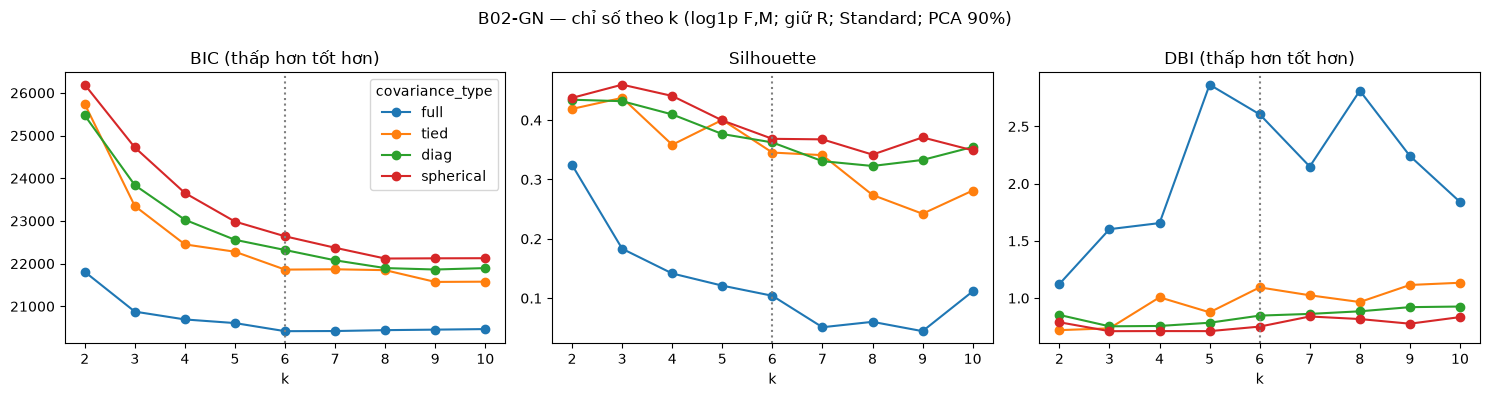

In [4]:
def sweep(Zs):
    rows = []
    for cov in COV_TYPES:
        for k in K_RANGE:
            gm = GaussianMixture(n_components=k, covariance_type=cov, n_init=N_INIT, max_iter=MAX_ITER, tol=TOL,
                                  reg_covar=REG_COVAR, init_params=INIT_PARAMS, random_state=RANDOM_STATE).fit(Zs)
            lab = gm.predict(Zs); sizes = np.bincount(lab, minlength=k)
            ok = len(np.unique(lab)) > 1
            rows.append({"covariance_type": cov, "k": k, "BIC": gm.bic(Zs), "AIC": gm.aic(Zs),
                         "Silhouette": silhouette_score(Zs, lab) if ok else np.nan,
                         "DBI": davies_bouldin_score(Zs, lab) if ok else np.nan,
                         "CHI": calinski_harabasz_score(Zs, lab) if ok else np.nan,
                         "min_cluster": int(sizes.min()), "converged": bool(gm.converged_)})
    return pd.DataFrame(rows)

def select(res, n):
    ok = res[res["converged"] & (res["min_cluster"] >= MIN_CLUSTER_FRAC * n)]
    return ok.loc[ok["BIC"].idxmin()]

res = sweep(Z)
best = select(res, len(X))
print(f"Chọn: {best['covariance_type']}, k={int(best['k'])}, BIC={best['BIC']:,.1f}, "
      f"Silhouette={best['Silhouette']:.4f}, cụm nhỏ nhất={int(best['min_cluster'])}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["BIC", "Silhouette", "DBI"]):
    for cov in COV_TYPES:
        s = res[res["covariance_type"] == cov]
        ax.plot(s["k"], s[col], marker="o", label=cov)
    ax.axvline(int(best["k"]), color="gray", ls=":")
    ax.set_xlabel("k"); ax.set_title(col + (" (thấp hơn tốt hơn)" if col in ("BIC", "DBI") else ""))
axes[0].legend(title="covariance_type")
plt.suptitle("B02-GN — chỉ số theo k (log1p F,M; giữ R; Standard; PCA 90%)")
plt.tight_layout(); plt.savefig(FIG / "gmm_metrics.png", dpi=150); plt.show()

**Nhận xét:** BIC thấp nhất ở `full`, k=6 (20.417,9) — **khác B01** (chọn `full`, k=4, BIC 24.347,1; lưu ý hai BIC không so được trực tiếp vì không gian dữ liệu khác nhau). Cụm nhỏ nhất 557 khách, không cụm nào bị loại theo quy tắc min 1%.

## Train mô hình cuối

In [5]:
model = Pipeline([("scaler", StandardScaler()),
                   ("pca", PCA(n_components=n_pc, svd_solver="full")),
                   ("gmm", GaussianMixture(n_components=int(best["k"]), covariance_type=best["covariance_type"],
                                            n_init=N_INIT, max_iter=MAX_ITER, tol=TOL, reg_covar=REG_COVAR,
                                            init_params=INIT_PARAMS, random_state=RANDOM_STATE))]).fit(X_t)
gm = model["gmm"]
labels = gm.predict(Z)
proba = gm.predict_proba(Z)
assert (model[:-1].transform(X_t) == Z).all()
print("Hội tụ:", gm.converged_, "| số vòng EM:", gm.n_iter_)
print(pd.Series(labels).value_counts().sort_index().rename("Số khách"))
print("Silhouette:", round(silhouette_score(Z, labels), 4), "| DBI:", round(davies_bouldin_score(Z, labels), 4))

Hội tụ: True | số vòng EM: 29
0    812
1    609
2    557
3    639
4    933
5    777
Name: Số khách, dtype: int64
Silhouette: 0.1041 | DBI: 2.606


**Nhận xét:** 6 cụm khá cân đối (557–933 khách, 12,9–21,6%), hội tụ sau 29 vòng EM. Silhouette 0,1041 cao hơn B01 (B01-GN trong repo ghi 0,3082 trên PCA, cần xem lại đơn vị đo — ở đây DBI 2,606 tệ hơn nhiều so với B01 (1,0652), cho thấy các cụm chồng lấn nhiều hơn khi Recency chưa log1p.

## Đối chiếu B01-GN

Dựng lại B01 (log1p cả R,F,M) ngay tại đây để so bằng ARI, cùng seed và quy tắc chọn.

In [6]:
X_t_b01 = np.log1p(X)
X_scaled_b01 = StandardScaler().fit_transform(X_t_b01)
cum_b01 = np.cumsum(PCA(svd_solver="full").fit(X_scaled_b01).explained_variance_ratio_)
n_pc_b01 = int(np.searchsorted(cum_b01, PCA_VAR) + 1)
Z_b01 = PCA(n_components=n_pc_b01, svd_solver="full").fit_transform(X_scaled_b01)
res_b01 = sweep(Z_b01); best_b01 = select(res_b01, len(X))
labels_b01 = GaussianMixture(n_components=int(best_b01["k"]), covariance_type=best_b01["covariance_type"],
                              n_init=N_INIT, max_iter=MAX_ITER, tol=TOL, reg_covar=REG_COVAR,
                              init_params=INIT_PARAMS, random_state=RANDOM_STATE).fit_predict(Z_b01)

print("Số PC: B02 =", Z.shape[1], "| B01 (dựng lại) =", Z_b01.shape[1])
print(f"B01 dựng lại: {best_b01['covariance_type']}, k={int(best_b01['k'])}, BIC={best_b01['BIC']:,.1f}")
print(f"B02           : {best['covariance_type']}, k={int(best['k'])}, BIC={best['BIC']:,.1f}")
print("ARI (B02-GN vs B01-GN):", round(adjusted_rand_score(labels, labels_b01), 4))

Số PC: B02 = 2 | B01 (dựng lại) = 2
B01 dựng lại: full, k=4, BIC=24,347.1
B02           : full, k=6, BIC=20,417.9
ARI (B02-GN vs B01-GN): 0.4541


**Nhận xét:** B02 ≠ B01: số cụm khác (6 so với 4), BIC khác (không gian khác nên không so trực tiếp được), và **ARI chỉ 0,4541** — khác biệt rõ, không phải biến thể tương đương. Giữ Recency ở thang gốc làm GMM chia nhỏ hơn và kém cân đối hơn (DBI tệ hơn): log1p Recency trong B01 có đóng góp thực sự, không phải bước thừa.

## Hồ sơ cụm

In [7]:
prof = X.assign(cluster=labels).groupby("cluster").agg(
    customers=("Monetary", "size"), Recency=("Recency", "median"),
    Frequency=("Frequency", "median"), Monetary=("Monetary", "median"),
    Monetary_sum=("Monetary", "sum"))
prof["customer_share_pct"] = (100 * prof["customers"] / len(X)).round(2)
prof["Monetary_share_pct"] = (100 * prof["Monetary_sum"] / prof["Monetary_sum"].sum()).round(2)
prof.drop(columns="Monetary_sum").round(1)

,customers,Recency,Frequency,Monetary,customer_share_pct,Monetary_share_pct
cluster,,,,,,
0,812,24.0,4.0,1280.8,18.8,22.5
1,609,285.0,1.0,237.4,14.1,2.2
2,557,53.0,1.0,261.9,12.9,1.9
3,639,64.0,3.0,1163.4,14.8,12.3
4,933,8.0,5.0,1657.3,21.6,54.1
5,777,157.0,2.0,468.8,18.0,7.1


**Nhận xét:** Cụm 4 (933 khách, 21,6%) là khách mua gần đây, thường xuyên, chi tiêu cao (Recency 8, Frequency 5, Monetary 1.657) — chiếm 54,1% Monetary. Cụm 1 và 2 (tổng 1.166 khách, 27%) chỉ mua 1 lần, Monetary thấp (237–262), chiếm chưa tới 4,1% Monetary. Vẫn chia được các mức trung gian như B01, nhưng không trùng nhóm.

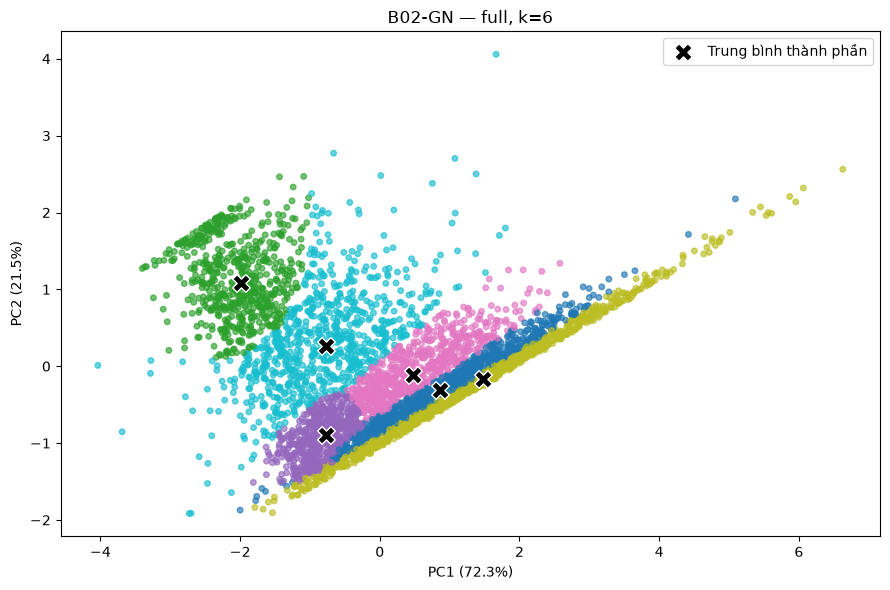

In [8]:
fig, ax = plt.subplots(figsize=(9, 6))
centers = gm.means_
sc = ax.scatter(Z[:, 0], Z[:, 1], c=labels, cmap="tab10", s=16, alpha=0.65)
ax.scatter(centers[:, 0], centers[:, 1], c="black", marker="X", s=160, edgecolors="white", label="Trung bình thành phần")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})"); ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
ax.set_title(f"B02-GN — {best['covariance_type']}, k={int(best['k'])}")
ax.legend(); plt.tight_layout(); plt.savefig(FIG / "gmm_clusters_pca.png", dpi=150); plt.show()

**Nhận xét:** Các cụm là những vùng liền kề, không tách bạch — khớp Silhouette thấp và DBI cao đã thấy ở trên; rõ hơn A01-DB/A02-KM (chỉ tách outlier) nhưng mờ hơn B01-GN.

## Lưu kết quả

In [9]:
res.to_csv(OUT / "gmm_b02_grid.csv", index=False)
pd.DataFrame({"CustomerID": df["CustomerID"], "cluster": labels, "max_proba": proba.max(axis=1).round(4)}) \
    .to_csv(OUT / "gmm_b02_labels.csv", index=False)
joblib.dump(model, "gmm_b02_model.pkl")
params = {"experiment": "B02-GN", "features": FEATURES, "log_cols": LOG_COLS, "scaler": "StandardScaler",
          "pca_variance": PCA_VAR, "n_components": n_pc, "pca_variance_kept": float(cum[n_pc - 1]),
          "covariance_type": best["covariance_type"], "k": int(best["k"]), "bic": float(best["BIC"]),
          "silhouette": float(best["Silhouette"]), "dbi": float(best["DBI"]),
          "ari_vs_b01_gn": float(adjusted_rand_score(labels, labels_b01))}
json.dump(params, open(OUT / "gmm_b02_params.json", "w", encoding="utf8"), ensure_ascii=False, indent=2)
print("Đã lưu:", sorted(p.name for p in OUT.iterdir()))

Đã lưu: ['gmm_b02_grid.csv', 'gmm_b02_labels.csv', 'gmm_b02_params.json']


**Nhận xét kết luận B02-GN:** Giữ Recency ở thang gốc (không log1p) làm GMM chia **6 cụm kém cân đối hơn** B01 về mặt chồng lấn (DBI 2,606 so với 1,0652), dù số khách mỗi cụm vẫn tương đối đều. ARI chỉ 0,4541 so với B01 cho thấy log1p Recency thay đổi đáng kể cách chia nhóm, không phải chi tiết nhỏ. Kết luận: nên giữ log1p Recency như B01 (nhánh chính), B02 chỉ nên dùng làm đối chứng trong báo cáo, không thay thế B01.